# 🧪 AICE Associate 모의고사 2 · 통신사 고객 이탈 예측 (이진분류) — 정답 및 해설

> 난이도 ★★★ (실제 시험 수준) · 14문항 · 100점 · 합격 80점 · 제한시간 90분

이 노트북은 **정답 코드 + 해설**입니다. 먼저 문제 노트북을 직접 풀고, 채점한 뒤에 보세요.
맨 아래 채점 셀을 실행하면 100점이 나와야 정상입니다.

---

## 시나리오
통신사 **'K텔레콤'** 은 해지할 것 같은 고객을 미리 찾아 혜택을 주려고 합니다.
고객 정보로 **이탈 여부 `Churn`(Yes/No)** 을 예측하는 분류 모델을 만드세요.

이번 회차의 함정: **숫자인데 문자로 읽히는 컬럼**, **결측이 대부분인 컬럼**, **불균형 타깃**, **스케일링 순서**

In [1]:
# [준비 셀] 문제가 아닙니다. 그대로 실행하세요.
import os, warnings
os.environ['OMP_NUM_THREADS'] = '1'         # macOS: XGBoost 와 PyTorch 를 한 노트북에서 쓸 때 멈춤 방지 (맨 처음 실행)
warnings.filterwarnings('ignore')            # 불필요한 경고 숨기기
import sys
sys.path.insert(0, '..')                    # 채점기(aice_check.py) 위치
DATA_DIR = '../../data/'

## 데이터 설명 — telecom_customers.csv

| 컬럼 | 설명 | 컬럼 | 설명 |
|---|---|---|---|
| customer_id | 고객 ID | paperless | 종이 없는 청구서 여부 |
| gender | 성별 | payment | 결제 방법 |
| senior | 고령자 여부 (1/0) | monthly_fee | 월 요금 |
| partner | 배우자 유무 | total_fee | 누적 요금 |
| dependents | 부양가족 유무 | num_tickets | 고객센터 상담 건수 |
| tenure_months | 가입 개월 수 | data_usage_gb | 월 데이터 사용량(GB) |
| contract | 약정 종류 | promo_code | 프로모션 코드 |
| internet | 인터넷 서비스 종류 | **Churn** | **이탈 여부 Yes/No ← 예측 대상** |
| streaming | 스트리밍 부가서비스 | | |

---
### 문항 1 &nbsp;<small>(4점)</small> &nbsp; 라이브러리 불러오기

**pandas → `pd`**, **numpy → `np`**, **matplotlib.pyplot → `plt`**, **seaborn → `sns`** 로 import 하세요.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

> **해설**
>
> 네 개를 한 셀에서 import 해도 됩니다. 별칭 오타만 조심하세요.

---
### 문항 2 &nbsp;<small>(5점)</small> &nbsp; 데이터 읽기

`DATA_DIR + 'telecom_customers.csv'` 를 읽어 **`df`** 에 저장하고, `head()` 와 `info()` 로 구조를 확인하세요.

In [3]:
df = pd.read_csv(DATA_DIR + 'telecom_customers.csv')
display(df.head())
df.info()

,customer_id,gender,senior,partner,dependents,tenure_months,contract,internet,streaming,paperless,payment,monthly_fee,total_fee,num_tickets,data_usage_gb,promo_code,Churn
0,C00001,Female,0,No,No,6,Month-to-month,Fiber optic,No,No,Mailed check,84.63,519.16,0,98.1,NaN,No
1,C00002,Male,0,No,No,15,Month-to-month,DSL,Yes,Yes,Credit card,68.60,1000.62,1,NaN,NaN,No
2,C00003,Male,0,Yes,Yes,31,Two year,Fiber optic,Yes,No,Bank transfer,89.75,2431.12,1,NaN,P10,No
3,C00004,Female,0,No,No,1,Month-to-month,DSL,Yes,Yes,Bank transfer,71.65,70.05,1,127.7,NaN,No
4,C00005,Male,0,No,No,3,Month-to-month,Fiber optic,No,Yes,Mailed check,79.75,237.26,1,31.0,NaN,Yes


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   customer_id    5000 non-null   object 
 1   gender         5000 non-null   object 
 2   senior         5000 non-null   int64  
 3   partner        5000 non-null   object 
 4   dependents     5000 non-null   object 
 5   tenure_months  5000 non-null   int64  
 6   contract       5000 non-null   object 
 7   internet       4925 non-null   object 
 8   streaming      5000 non-null   object 
 9   paperless      5000 non-null   object 
 10  payment        5000 non-null   object 
 11  monthly_fee    5000 non-null   float64
 12  total_fee      5000 non-null   object 
 13  num_tickets    5000 non-null   int64  
 14  data_usage_gb  4850 non-null   float64
 15  promo_code     1450 non-null   object 
 16  Churn          5000 non-null   object 
dtypes: float64(2), int64(3), object(12)
memory usage: 66

> **해설**
>
> `info()` 에서 **`total_fee` 가 object** 로 나오는 걸 꼭 발견해야 합니다. 요금은 숫자여야 하는데 문자열이 섞였다는 신호입니다 (4번 문항).

---
### 문항 3 &nbsp;<small>(7점)</small> &nbsp; 타깃 분포 확인

- `Churn` 분포를 seaborn **countplot** 으로 그리세요.
- 전체 고객 중 **이탈(`'Yes'`) 고객 비율**을 구해 **소수 셋째 자리에서 반올림**(`round(값, 3)`)하여 **`churn_rate`** 에 저장하세요.

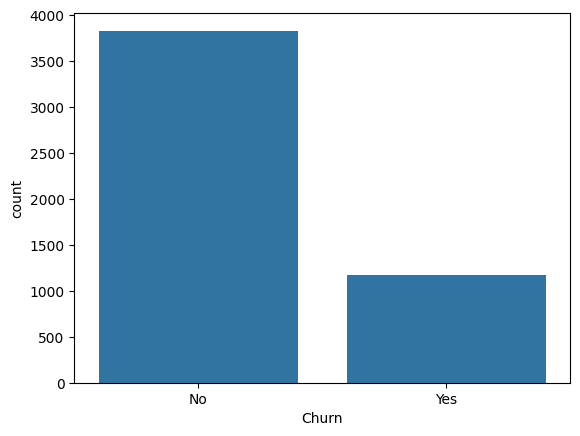

0.234


In [4]:
sns.countplot(data=df, x='Churn')
plt.show()

churn_rate = round(df['Churn'].value_counts(normalize=True)['Yes'], 3)
print(churn_rate)

> **해설**
>
> - `value_counts(normalize=True)` 는 개수 대신 **비율**을 돌려줍니다.
> - 다른 정답: `round((df['Churn'] == 'Yes').mean(), 3)` — True=1, False=0 이라 평균이 곧 비율입니다.
> - 이탈 고객이 약 23% → **불균형** 데이터입니다. 그래서 9번에서 `stratify` 를 씁니다.

---
### 문항 4 &nbsp;<small>(7점)</small> &nbsp; 데이터 타입 변환

`total_fee` 는 숫자여야 하지만 공백 문자열 `' '` 이 섞여 object 타입입니다.
**`' '` 을 `'0'` 으로 바꾼 뒤 float 로 변환**하여 **`df['total_fee']`** 에 다시 저장하세요.

In [5]:
print((df['total_fee'] == ' ').sum(), '개의 공백')
df['total_fee'] = df['total_fee'].replace(' ', '0').astype(float)
print(df['total_fee'].dtype)

28 개의 공백
float64


> **해설**
>
> - 바로 `astype(float)` 를 하면 `ValueError: could not convert string to float: ' '` 가 납니다.
> - 공백인 고객은 **가입 0개월(신규)** 고객이라 누적 요금이 0 인 게 자연스럽습니다.
> - 다른 정답: `df['total_fee'] = pd.to_numeric(df['total_fee'], errors='coerce').fillna(0)`
> - ⚠️ `df['total_fee'].replace(' ', '0', inplace=True)` 처럼 **컬럼에 inplace** 를 쓰는 방식은 pandas 버전에 따라 반영이 안 될 수 있습니다. **`df['컬럼'] = ...` 으로 다시 대입**하는 습관이 가장 안전합니다.

---
### 문항 5 &nbsp;<small>(7점)</small> &nbsp; 결측치 처리

아래 순서로 처리한 결과를 **`df1`** 에 저장하세요 (`df` 는 그대로 둡니다).
1. 결측치 비율이 **50% 이상**인 컬럼과 **`customer_id`** 컬럼을 삭제
2. 남은 결측치는 **수치형 컬럼 → 중앙값(median)**, **object 컬럼 → 최빈값(mode)** 으로 채우기

In [6]:
print(df.isna().mean().round(3))

drop_cols = df.columns[df.isna().mean() >= 0.5].tolist() + ['customer_id']
print('삭제할 컬럼:', drop_cols)
df1 = df.drop(drop_cols, axis=1)

for col in df1.columns[df1.isna().any()]:
    if df1[col].dtype == 'object':
        df1[col] = df1[col].fillna(df1[col].mode()[0])
    else:
        df1[col] = df1[col].fillna(df1[col].median())

print(df1.isna().sum().sum())

customer_id      0.000
gender           0.000
senior           0.000
partner          0.000
dependents       0.000
tenure_months    0.000
contract         0.000
internet         0.015
streaming        0.000
paperless        0.000
payment          0.000
monthly_fee      0.000
total_fee        0.000
num_tickets      0.000
data_usage_gb    0.030
promo_code       0.710
Churn            0.000
dtype: float64
삭제할 컬럼: ['promo_code', 'customer_id']
0


> **해설**
>
> - `isna().mean()` = 컬럼별 결측 **비율**. `promo_code` 가 72% 라서 삭제 대상입니다.
> - `mode()` 는 Series 를 돌려주므로 **`[0]`** 으로 첫 번째 값을 꺼내야 합니다. `fillna(df1[col].mode())` 는 인덱스 0번 행만 채우는 흔한 실수입니다.
> - 결측이 있는 컬럼(`internet`, `data_usage_gb`)만 직접 써도 정답입니다:
>   `df1['internet'] = df1['internet'].fillna(df1['internet'].mode()[0])`
>   `df1['data_usage_gb'] = df1['data_usage_gb'].fillna(df1['data_usage_gb'].median())`

---
### 문항 6 &nbsp;<small>(7점)</small> &nbsp; 라벨 인코딩

sklearn 의 **LabelEncoder** 를 **`le`** 로 만들어 `df1` 의 **`Churn`** 을 숫자(No→0, Yes→1)로 바꾸고 **`df1['Churn']`** 에 저장하세요.

In [7]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df1['Churn'] = le.fit_transform(df1['Churn'])
print(le.classes_, df1['Churn'].value_counts().to_dict())

['No' 'Yes'] {0: 3830, 1: 1170}


> **해설**
>
> - LabelEncoder 는 **알파벳 순서**로 0, 1, 2… 를 붙입니다 (No=0, Yes=1).
> - 다른 방법: `df1['Churn'] = df1['Churn'].map({'No': 0, 'Yes': 1})` — 문제에서 LabelEncoder 를 지정했다면 지시를 따르세요.

---
### 문항 7 &nbsp;<small>(7점)</small> &nbsp; 시각화 + 그룹 통계 해석

- x=`Churn`, y=`tenure_months` 로 seaborn **boxplot** 을 그리세요.
- **groupby** 를 이용해 **이탈 고객(Churn=1)의 `tenure_months` 중앙값**을 구해 **`churn_tenure_median`** 에 저장하세요.

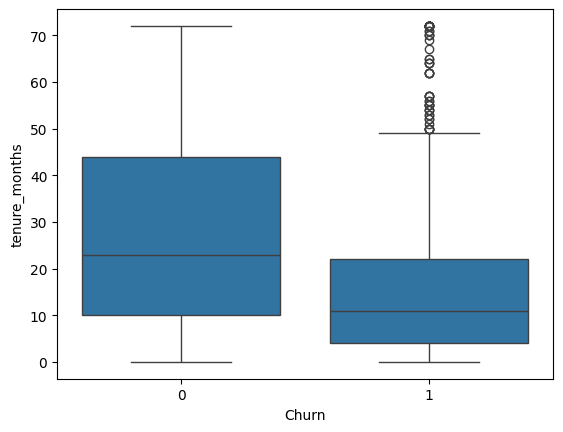

11.0


In [8]:
sns.boxplot(data=df1, x='Churn', y='tenure_months')
plt.show()

churn_tenure_median = df1.groupby('Churn')['tenure_months'].median()[1]
print(churn_tenure_median)

> **해설**
>
> - `groupby('Churn')['tenure_months'].median()` 은 Churn 값(0, 1)별 중앙값 Series 입니다. `[1]` 로 이탈 그룹을 꺼냅니다.
> - 해석: 이탈 고객은 가입 기간이 훨씬 짧습니다 → 가입 초기 고객 관리가 중요하다는 인사이트.
> - 다른 정답: `df1[df1['Churn'] == 1]['tenure_months'].median()`

---
### 문항 8 &nbsp;<small>(7점)</small> &nbsp; 원-핫 인코딩

`df1` 의 **object 컬럼 전부**를 **get_dummies** 로 원-핫 인코딩하되 **`drop_first=True`** 를 적용하여 **`df_preset`** 에 저장하세요.

In [9]:
cols = df1.select_dtypes('object').columns
df_preset = pd.get_dummies(df1, columns=cols, drop_first=True)
print(df_preset.shape)

(5000, 19)


> **해설**
>
> - `drop_first=True` 는 범주마다 첫 번째 더미 컬럼을 하나 뺍니다 (예: gender_Female 삭제, gender_Male 만 남음). 나머지로 알 수 있는 정보라 중복을 줄입니다.
> - 지시를 빼먹으면 컬럼 수가 달라져 이후 문항까지 연쇄로 틀립니다.

---
### 문항 9 &nbsp;<small>(8점)</small> &nbsp; 학습/평가 데이터 분리

`df_preset` 에서 **`Churn`** 을 y, 나머지를 X 로 하여 **test_size=0.2, stratify=y, random_state=42** 로 나누고
**`X_train, X_test, y_train, y_test`** 에 저장하세요.

In [10]:
from sklearn.model_selection import train_test_split

X = df_preset.drop('Churn', axis=1)
y = df_preset['Churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(y_train.mean().round(3), y_test.mean().round(3))

0.234 0.234


> **해설**
>
> - `stratify=y` 는 train/test 의 이탈 비율을 원본과 똑같이 맞춥니다. 불균형 분류에서 자주 지시됩니다.
> - `stratify=y_train` 이나 `stratify=X` 로 쓰는 실수 주의.

---
### 문항 10 &nbsp;<small>(7점)</small> &nbsp; 스케일링

**StandardScaler** 를 **`scaler`** 로 만들어 **X_train 으로 fit** 하고, 변환 결과를 **`X_train_s`**, **`X_test_s`** 에 저장하세요.

In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

> **해설**
>
> - **train 에는 `fit_transform`, test 에는 `transform` 만.** test 로 다시 fit 하면 평가 데이터 정보가 새어 들어갑니다(데이터 누수). 시험 단골 함정입니다.
> - 결과는 numpy 배열이 됩니다 (컬럼명 없음).

---
### 문항 11 &nbsp;<small>(8점)</small> &nbsp; 머신러닝 모델 학습

**RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)** 를 **`rf`** 로 만들고 **`X_train_s, y_train`** 으로 학습하세요.

In [12]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42)
rf.fit(X_train_s, y_train)

,n_estimators,200
,criterion,'gini'
,max_depth,8
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


> **해설**
>
> - 분류 문제이므로 **Classifier**. 스케일링한 `X_train_s` 로 학습했으니 예측도 `X_test_s` 로 해야 합니다.
> - 트리 모델은 사실 스케일링이 필요 없지만, 시험에서는 지시받은 데이터를 그대로 쓰세요.

---
### 문항 12 &nbsp;<small>(9점)</small> &nbsp; 머신러닝 모델 평가

`rf` 로 **`X_test_s`** 를 예측해 **`rf_pred`** 에 저장하고,
**정확도 → `rf_acc`**, **F1 → `rf_f1`**, **혼동행렬 → `cm`** 을 구하세요. (cm 은 heatmap 으로 그려 보세요)

accuracy 0.792 | f1 0.350
              precision    recall  f1-score   support

           0       0.81      0.96      0.88       766
           1       0.65      0.24      0.35       234

    accuracy                           0.79      1000
   macro avg       0.73      0.60      0.61      1000
weighted avg       0.77      0.79      0.75      1000



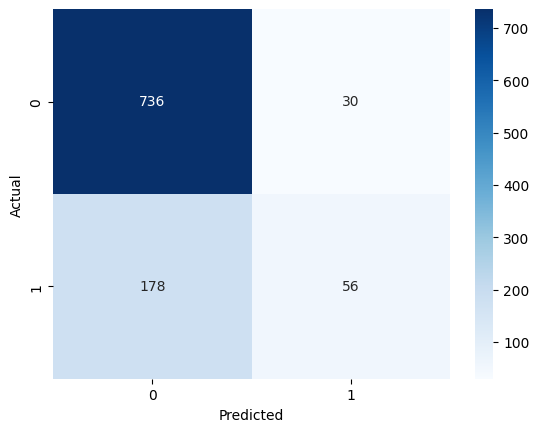

In [13]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

rf_pred = rf.predict(X_test_s)
rf_acc = accuracy_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
cm = confusion_matrix(y_test, rf_pred)
print(f'accuracy {rf_acc:.3f} | f1 {rf_f1:.3f}')
print(classification_report(y_test, rf_pred))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.show()

> **해설**
>
> - 정확도는 80% 를 넘지만 F1 은 훨씬 낮습니다 → **불균형 데이터에서 정확도만 보면 안 되는 이유**.
> - 혼동행렬: 행 = 실제, 열 = 예측. `[[TN, FP], [FN, TP]]`.
> - `fmt='d'` 를 주면 heatmap 숫자가 정수로 표시됩니다.

---
### 문항 13 &nbsp;<small>(10점)</small> &nbsp; 딥러닝 모델 학습 (PyTorch)

- **`torch.manual_seed(42)`** 실행 후 텐서로 바꾸세요: X_train_s, X_test_s → **`X_train_t`**, **`X_test_t`** (float32) / y_train, y_test → **`y_train_t`**, **`y_test_t`** (float32, 모양 **(N, 1)**)
- **`train_loader`**: TensorDataset(X_train_t, y_train_t), **batch_size=32, shuffle=True**
- **`model`** = nn.Sequential: **Linear(입력 수, 32)** → **ReLU** → **Dropout(0.3)** → **Linear(32, 16)** → **ReLU** → **Linear(16, 1)** (출력층에 Sigmoid 를 **넣지 마세요**)
- **`loss_fn`** = **nn.BCEWithLogitsLoss()**, **`optimizer`** = **Adam(lr=0.001)**
- **epochs=30**, 매 epoch 마다 **`history`** 딕셔너리의 **`'loss'`**(배치 손실 평균), **`'val_loss'`**(eval 모드, X_test_t 전체)에 추가

In [14]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=32, shuffle=True)

model = nn.Sequential(
    nn.Linear(X_train_t.shape[1], 32), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(32, 16), nn.ReLU(),
    nn.Linear(16, 1),                      # 출력 = logit (시그모이드 전 값)
)
loss_fn = nn.BCEWithLogitsLoss()           # 시그모이드 + BCE 를 한 번에
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

history = {'loss': [], 'val_loss': []}
for epoch in range(30):
    model.train()
    batch_losses = []
    for xb, yb in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(xb), yb)
        loss.backward()
        optimizer.step()
        batch_losses.append(loss.item())
    model.eval()
    with torch.no_grad():
        history['val_loss'].append(loss_fn(model(X_test_t), y_test_t).item())
    history['loss'].append(sum(batch_losses) / len(batch_losses))

print(f"loss {history['loss'][-1]:.4f} | val_loss {history['val_loss'][-1]:.4f}")

loss 0.4117 | val_loss 0.4330


> **해설**
>
> - **이진분류 = 출력 `Linear(…, 1)` + `nn.BCEWithLogitsLoss()`**. 이 짝을 꼭 외우세요.
> - **왜 Sigmoid 를 안 붙이나?** `BCEWithLogitsLoss` 가 내부에서 시그모이드를 계산합니다 (수치적으로 더 안정적). 출력층에 `nn.Sigmoid()` 까지 넣으면 **시그모이드를 두 번** 거쳐 학습이 잘 안 됩니다. 시그모이드를 층에 넣고 싶다면 손실을 `nn.BCELoss()` 로 짝을 맞춰야 합니다.
> - BCE 계열 손실은 y 를 **float** 로, 출력과 같은 **(N, 1)** 모양으로 받습니다. `long` 으로 주면 에러.
> - 스케일링한 `X_train_s` 는 이미 numpy 배열이라 `.values` 없이 바로 `torch.tensor(...)` 합니다. `y_train` 은 pandas Series 라 `.values`.

---
### 문항 14 &nbsp;<small>(7점)</small> &nbsp; 딥러닝 예측 + 평가

- eval 모드 + `torch.no_grad()` 에서 `model(X_test_t)` 의 출력에 **`torch.sigmoid`** 를 씌워 확률을 구하고, **0.5 보다 크면 1, 아니면 0** 인 **1차원 정수 numpy 배열**을 **`dnn_pred`** 에 저장하세요.
- 정확도를 **`dnn_acc`** 에 저장하고, history 의 **loss / val_loss** 그래프를 그리세요 (title **'Loss'**, xlabel **'Epochs'**, ylabel **'Loss'**, legend **['loss', 'val_loss']**).

DNN accuracy: 0.803


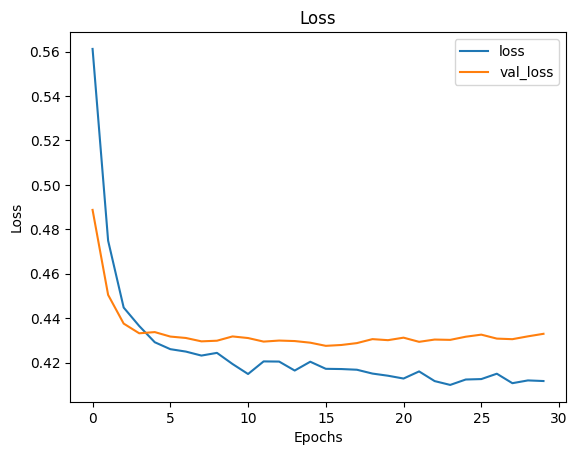

In [15]:
model.eval()
with torch.no_grad():
    proba = torch.sigmoid(model(X_test_t))          # logit → 확률(0~1)
dnn_pred = (proba > 0.5).int().numpy().ravel()
dnn_acc = accuracy_score(y_test, dnn_pred)
print(f'DNN accuracy: {dnn_acc:.3f}')

plt.plot(history['loss'])
plt.plot(history['val_loss'])
plt.title('Loss'); plt.xlabel('Epochs'); plt.ylabel('Loss')
plt.legend(['loss', 'val_loss'])
plt.show()

> **해설**
>
> - 모델 출력은 **logit**(시그모이드 전 값, -∞~∞)입니다. 확률로 보려면 `torch.sigmoid`. 사실 `logit > 0` 과 `sigmoid(logit) > 0.5` 는 같은 판정입니다.
> - `(proba > 0.5)` 는 bool 텐서 → `.int()` 로 0/1, `.numpy().ravel()` 로 `(1000,)` 1차원 배열.
> - 다중분류였다면 `argmax(dim=1)` 을 씁니다 (모의고사 3).

---
## 🏁 채점
아래 셀을 실행하면 문항별 결과와 총점이 나옵니다. 틀린 문항은 → 뒤의 이유를 읽고 고쳐 본 뒤 다시 채점해 보세요.

In [16]:
import aice_check
aice_check.grade_exam2(globals())

📋 모의고사 2 · 고객 이탈 예측 (이진분류) 채점 결과
────────────────────────────────────────────────────────────────
✅  1번 [ 4/ 4점] pd, np, plt, sns import
✅  2번 [ 5/ 5점] telecom_customers.csv 읽기 → df
✅  3번 [ 7/ 7점] 이탈('Yes') 비율 → churn_rate (소수 셋째 자리 반올림)
✅  4번 [ 7/ 7점] total_fee 의 ' ' 를 0 으로 바꾸고 float 변환 (df 에 반영)
✅  5번 [ 7/ 7점] 결측 50% 이상 컬럼·customer_id 삭제, 수치형 중앙값·범주형 최빈값 채우기 → df1
✅  6번 [ 7/ 7점] LabelEncoder 로 Churn 인코딩 → le, df1["Churn"]
✅  7번 [ 7/ 7점] 이탈 고객(Churn=1)의 tenure_months 중앙값 → churn_tenure_median
✅  8번 [ 7/ 7점] object 컬럼 원-핫 인코딩(drop_first=True) → df_preset
✅  9번 [ 8/ 8점] train_test_split(test_size=0.2, stratify=y, random_state=42)
✅ 10번 [ 7/ 7점] StandardScaler: train 으로 fit → X_train_s, X_test_s
✅ 11번 [ 8/ 8점] RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42) → rf
✅ 12번 [ 9/ 9점] 예측 rf_pred, accuracy → rf_acc, f1 → rf_f1, 혼동행렬 → cm
✅ 13번 [10/10점] PyTorch 이진분류 DNN 학습 (BCEWithLogitsLoss) → model, history
✅ 14번 [ 7/ 7점] sigmoid > 0.5 예측 → dnn_pred (1차원 0/1), accuracy → d

100